#Introduction
The Credit Default Classification dataset contains information about customers, their income, credit scores, loan amounts, and loan repayment status.

The main objective of this project is to understand the dataset, perform data preprocessing, and analyze the data using univariate, bivariate, and multivariate analysis.

The analysis helps us understand customer information and identify patterns related to loan defaults.

#1. Importing Required Libraries
Python libraries are used to perform data analysis and visualization.

Pandas: Used to read and manipulate data.

NumPy: Used for numerical operations.

Matplotlib: Used to create graphs.

Seaborn: Used for statistical data visualization.

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully")

All libraries imported successfully


## 2. Loading the Dataset

In this step, we upload the CSV file into Google Colab and read it using the Pandas library.

The dataset is stored in a DataFrame for further analysis.

In [31]:
df = pd.read_csv("/content/credit_default_classification.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


## 3. Viewing the Dataset

The head() function displays the first five rows of the dataset.

This helps us understand the structure and the type of information available in the dataset.

In [32]:
df.head()

,age,loan_amount_k,credit_score,home_owner,num_open_accounts,income_k,loan_purpose,defaulted,customer,months_since_delinq,credit_score_dup
0,23.0,449.04,792.0,Ys,4.0,85.68,Debt cnsolidation,0.0,CR30000,3.0,792.0
1,62.0,122.05,637.0,Yes,9.0,41.04,Home improvemnt,0.0,CR30001,1.0,637.0
2,22.0,177.22,365.0,NaN,8.0,82.81,HOME IMPROVEMENT,0.0,CR30002,12.0,365.0
3,73.0,475.14,721.0,NO,7.0,142.80,Business,NaN,CR30003,6.0,721.0
4,49.0,289.66,839.0,NO,8.0,49.13,Home improvement,0.0,CR30004,0.0,839.0


## 4. Dataset Shape

The shape function gives the total number of rows and columns in the dataset.

Rows represent records, and columns represent features or attributes.

In [33]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 257
Number of columns: 11


## 5. Dataset Information

The info() function displays the column names, data types, and number of non-null values.

It helps us identify numerical and categorical columns and understand whether any values are missing.

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  239 non-null    float64
 1   loan_amount_k        244 non-null    float64
 2   credit_score         233 non-null    float64
 3   home_owner           242 non-null    object 
 4   num_open_accounts    244 non-null    float64
 5   income_k             236 non-null    float64
 6   loan_purpose         233 non-null    object 
 7   defaulted            236 non-null    float64
 8   customer             246 non-null    object 
 9   months_since_delinq  246 non-null    float64
 10  credit_score_dup     233 non-null    float64
dtypes: float64(8), object(3)
memory usage: 22.2+ KB


## 6. Statistical Summary

The describe() function provides statistical information about numerical columns.

It displays count, mean, standard deviation, minimum, maximum, and quartile values.

In [35]:
df.describe()

,age,loan_amount_k,credit_score,num_open_accounts,income_k,defaulted,months_since_delinq,credit_score_dup
count,239.000000,244.000000,233.000000,244.000000,236.000000,236.000000,246.000000,233.000000
mean,52.338912,247.040574,565.751073,5.122951,52.083686,0.118644,4.252033,565.751073
std,19.582357,144.200185,160.597692,2.575855,30.494393,0.324057,4.238008,160.597692
min,18.000000,2.090000,303.000000,1.000000,-35.560000,0.000000,0.000000,303.000000
25%,36.000000,126.932500,420.000000,3.000000,31.955000,0.000000,1.000000,420.000000
50%,54.000000,246.840000,570.000000,5.000000,51.475000,0.000000,3.000000,570.000000
75%,67.000000,367.065000,706.000000,7.000000,73.907500,0.000000,6.000000,706.000000
max,84.000000,499.820000,847.000000,9.000000,142.800000,1.000000,12.000000,847.000000


## 7. Checking Missing Values

Missing values are empty cells in a dataset. They can affect the accuracy of data analysis.

In this step, we check the number of missing values present in each column.

In [36]:
df.isnull().sum()

,0
age,18
loan_amount_k,13
credit_score,24
home_owner,15
num_open_accounts,13
income_k,21
loan_purpose,24
defaulted,21
customer,11
months_since_delinq,11


## 8. Checking Duplicate Records

Duplicate records are repeated rows in a dataset.

In this step, we identify the duplicate records to avoid repeated information during analysis.

In [38]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 7


## 9. Removing Duplicate Records

Duplicate rows can affect the results of data analysis.

Therefore, we remove exact duplicate rows using the drop_duplicates() function.

In [39]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (250, 11)


## 10. Handling Inconsistent Categorical Values

Categorical values sometimes contain different spellings or uppercase and lowercase variations.

For example, Yes, YES, Ys and Ye represent the same category.

We standardize these values to maintain consistency in the dataset.

In [64]:
# Correct home_owner values

df['home_owner'] = df['home_owner'].str.strip().str.lower()

df['home_owner'] = df['home_owner'].replace({
    'yes': 'Yes',
    'ye': 'Yes',
    'ys': 'Yes',
    'es': 'Yes',
    'no': 'No',
    'n': 'No',
    'o': 'No'
})


# Correct loan_purpose values

df['loan_purpose'] = df['loan_purpose'].str.strip().str.lower()

df['loan_purpose'] = df['loan_purpose'].replace({
    'business': 'Business',
    'busines': 'Business',
    'buiness': 'Business',
    'bsiness': 'Business',
    'usiness': 'Business',
    'busness': 'Business',
    'busiess': 'Business',

    'eucation': 'Education',
    'edcation': 'Education',
    'educatio': 'Education',
    'educatin': 'Education',
    'education': 'Education',
    'eduction': 'Education',
    'ducation': 'Education',

    'car': 'Car',
    'cr': 'Car',
    'ar': 'Car',

    'home improvement': 'Home improvement',
    'home improvemnt': 'Home improvement',
    'hom improvement': 'Home improvement',
    'hoe improvement': 'Home improvement',
    'hme improvement': 'Home improvement',
    'home imrovement': 'Home improvement',
    'ome improvement': 'Home improvement',
    'home imprvement': 'Home improvement',

    'debt consolidation': 'Debt consolidation',
    'debt cnsolidation': 'Debt consolidation',
    'dbt consolidation': 'Debt consolidation',
    'debt consolidaton': 'Debt consolidation',
    'debt consolidtion': 'Debt consolidation'
})


# Display corrected categories

print("Home Owner Categories:")
print(df['home_owner'].value_counts(dropna=False))

print("\nLoan Purpose Categories:")
print(df['loan_purpose'].value_counts(dropna=False))

Home Owner Categories:
home_owner
No     137
Yes     94
Name: count, dtype: int64

Loan Purpose Categories:
loan_purpose
Business              69
Home improvement      43
Car                   41
Debt consolidation    39
Education             39
Name: count, dtype: int64


## 11. Handling Invalid Income Values

The income_k column contains negative values.

Since negative income is not valid for this dataset, we treat these values as invalid and replace them with missing values.

After that, we can handle them using an appropriate statistical method.

In [41]:
print("Negative income values:",
      (df['income_k'] < 0).sum())

df.loc[df['income_k'] < 0, 'income_k'] = np.nan

print("Invalid income values replaced with missing values.")

Negative income values: 14
Invalid income values replaced with missing values.


## 12. Handling Missing Target Values

The defaulted column represents whether a customer has defaulted on a loan.

Since this is the target column, we should not guess or replace its missing values.

Therefore, we remove the rows where the target value is missing.

In [42]:
df = df.dropna(subset=['defaulted'])

df['defaulted'] = df['defaulted'].astype(int)

print("Missing target values handled.")
print("Remaining rows:", len(df))

Missing target values handled.
Remaining rows: 231


## 13. Handling Remaining Missing Values

Missing numerical values are filled using the median.

Missing categorical values are filled using the mode.

The median is used because it is less affected by extreme values. The mode is used to fill missing categorical values with the most frequently occurring category.

Customer identification is not used for statistical analysis, so its missing values are not required to be filled.

In [43]:
# Fill numerical missing values with median

numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    if col != 'defaulted':
        df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values with mode

categorical_columns = ['home_owner', 'loan_purpose']

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:")
print(df.isnull().sum())

Remaining missing values:
age                     0
loan_amount_k           0
credit_score            0
home_owner              0
num_open_accounts       0
income_k                0
loan_purpose            0
defaulted               0
customer               11
months_since_delinq     0
credit_score_dup        0
dtype: int64


## 14. Removing Customer ID and Creating a New ID Column

The existing customer column contains customer identification values.

In this step, we remove the existing customer column and create a new ID column using NumPy's arange() function.

The new ID column contains sequential numbers starting from 1. This makes the dataset easier to identify and manage.

In [44]:
# Drop the existing customer column
df = df.drop(columns=['customer'])

# Create a new ID column using NumPy arange()
df.insert(0, 'ID', np.arange(1, len(df) + 1))

# Display the updated dataset
df.head()

,ID,age,loan_amount_k,credit_score,home_owner,num_open_accounts,income_k,loan_purpose,defaulted,months_since_delinq,credit_score_dup
0,1,23.0,449.04,792.0,Yes,4.0,85.68,Debt consolidation,0,3.0,792.0
1,2,62.0,122.05,637.0,Yes,9.0,41.04,Home improvement,0,1.0,637.0
2,3,22.0,177.22,365.0,No,8.0,82.81,Home improvement,0,12.0,365.0
4,4,49.0,289.66,839.0,No,8.0,49.13,Home improvement,0,0.0,839.0
5,5,66.0,183.52,792.0,Yes,5.0,68.43,Car,0,12.0,792.0


## 15. Final Cleaned Dataset

After completing data preprocessing, we check the dataset again.

This step ensures that duplicate records and missing values have been handled properly and that the dataset is ready for analysis.

In [45]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

df.head()

Final Dataset Shape: (231, 11)

Missing Values:
ID                     0
age                    0
loan_amount_k          0
credit_score           0
home_owner             0
num_open_accounts      0
income_k               0
loan_purpose           0
defaulted              0
months_since_delinq    0
credit_score_dup       0
dtype: int64

Duplicate Rows: 0


,ID,age,loan_amount_k,credit_score,home_owner,num_open_accounts,income_k,loan_purpose,defaulted,months_since_delinq,credit_score_dup
0,1,23.0,449.04,792.0,Yes,4.0,85.68,Debt consolidation,0,3.0,792.0
1,2,62.0,122.05,637.0,Yes,9.0,41.04,Home improvement,0,1.0,637.0
2,3,22.0,177.22,365.0,No,8.0,82.81,Home improvement,0,12.0,365.0
4,4,49.0,289.66,839.0,No,8.0,49.13,Home improvement,0,0.0,839.0
5,5,66.0,183.52,792.0,Yes,5.0,68.43,Car,0,12.0,792.0


## 16. Saving the Preprocessed Dataset

After completing data preprocessing, we save the cleaned dataset as a CSV file.

This file contains the cleaned data without missing values or duplicate rows. We will use this preprocessed dataset for further data analysis.

In [46]:
# Save the preprocessed dataset as a CSV file
df.to_csv('preprocessed_credit_default.csv', index=False)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


# Data Analysis

After completing data preprocessing, we load the preprocessed CSV file.

Now, we perform three types of data analysis:

1. Univariate Analysis
2. Bivariate Analysis
3. Multivariate Analysis

These analyses help us understand the data, identify relationships between variables, and find patterns related to loan default.

In [47]:
import pandas as pd

# Load the preprocessed CSV file
df = pd.read_csv("/content/preprocessed_credit_default.csv")

# Display the first five rows
df.head()

,ID,age,loan_amount_k,credit_score,home_owner,num_open_accounts,income_k,loan_purpose,defaulted,months_since_delinq,credit_score_dup
0,1,23.0,449.04,792.0,Yes,4.0,85.68,Debt consolidation,0,3.0,792.0
1,2,62.0,122.05,637.0,Yes,9.0,41.04,Home improvement,0,1.0,637.0
2,3,22.0,177.22,365.0,No,8.0,82.81,Home improvement,0,12.0,365.0
3,4,49.0,289.66,839.0,No,8.0,49.13,Home improvement,0,0.0,839.0
4,5,66.0,183.52,792.0,Yes,5.0,68.43,Car,0,12.0,792.0


# 17. Univariate Analysis

Univariate analysis is a type of data analysis that studies one variable at a time.

It helps us understand the distribution, frequency, average, minimum, and maximum values of individual columns.

In this project, we analyze numerical and categorical variables separately.

## 17.1 Numerical Variable Analysis

Numerical variables contain values that can be measured or counted.

In this step, we calculate the mean, median, minimum, and maximum values of numerical columns.

In [48]:
numeric_columns = [
    'age',
    'loan_amount_k',
    'credit_score',
    'num_open_accounts',
    'income_k',
    'months_since_delinq'
]

df[numeric_columns].describe()

,age,loan_amount_k,credit_score,num_open_accounts,income_k,months_since_delinq
count,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000
mean,52.714286,244.122338,563.082251,5.151515,57.373485,4.212121
std,18.969443,139.186419,153.936625,2.493206,23.974163,4.222407
min,18.000000,2.090000,303.000000,1.000000,4.210000,0.000000
25%,38.000000,127.875000,431.000000,3.000000,42.525000,1.000000
50%,54.000000,247.130000,568.000000,5.000000,55.865000,3.000000
75%,67.000000,358.775000,684.500000,7.000000,72.905000,6.000000
max,84.000000,499.820000,847.000000,9.000000,129.960000,12.000000


## 17.2 Histogram Analysis

A histogram is a graph used to show the distribution of numerical data.

It helps us understand how frequently different values occur in a column.

We use histograms to analyze the age, loan amount, credit score, and income of customers.

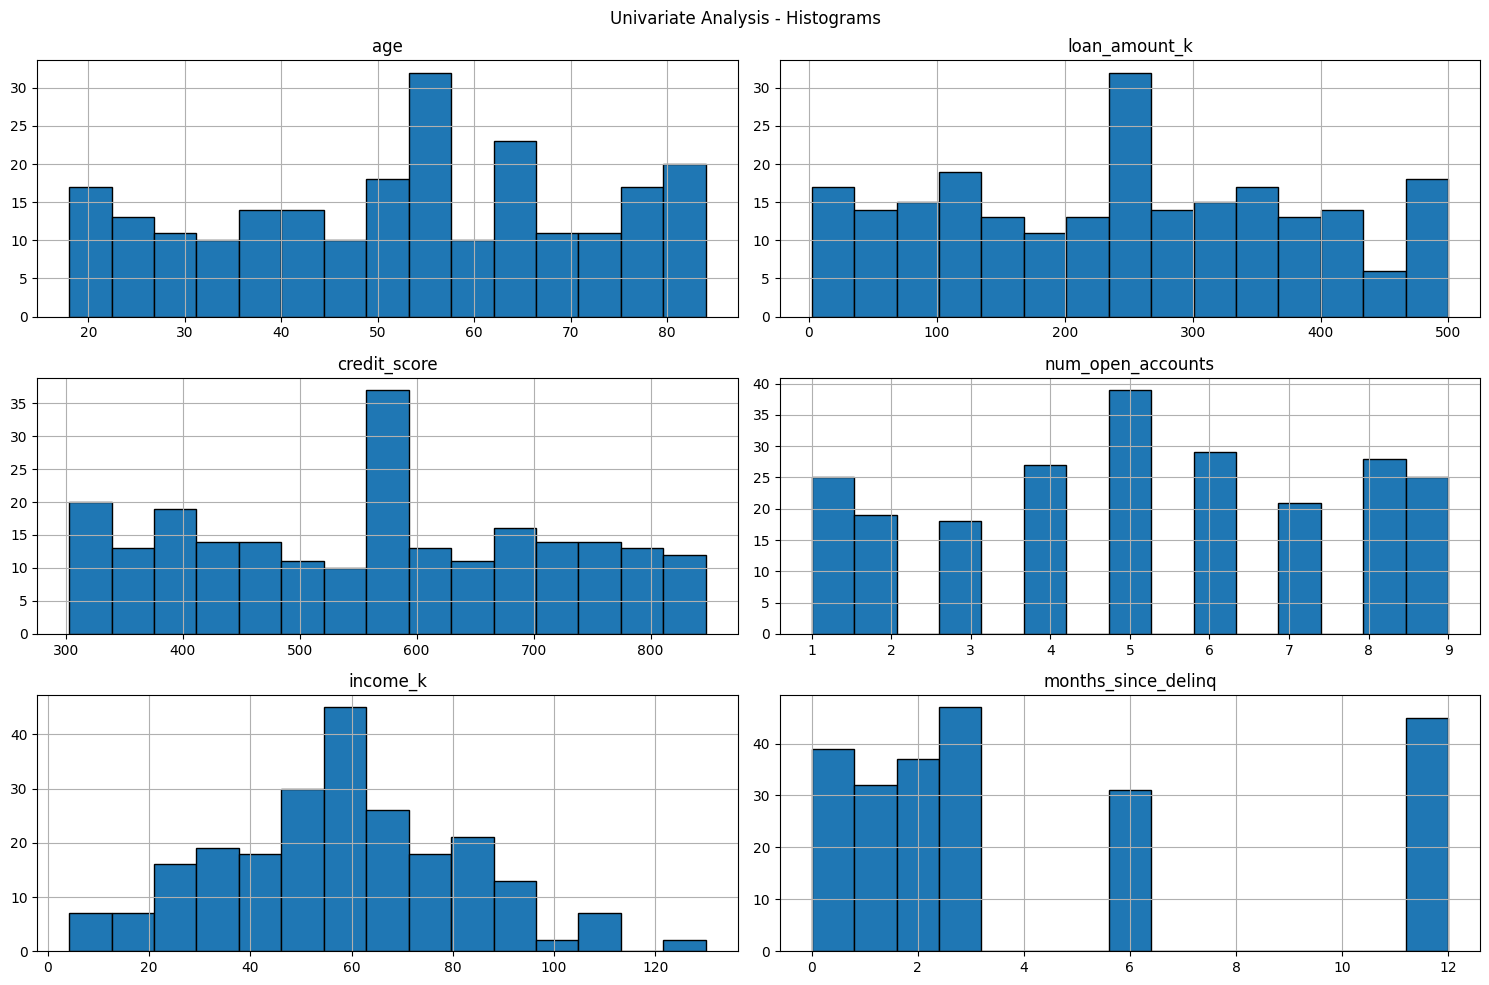

In [49]:
df[numeric_columns].hist(
    figsize=(15, 10),
    bins=15,
    edgecolor='black'
)

plt.suptitle("Univariate Analysis - Histograms")
plt.tight_layout()
plt.show()

## 17.3 Boxplot Analysis

A boxplot is used to understand the spread of numerical data.

It displays the minimum, maximum, median, and quartiles. It also helps identify possible outliers in the dataset.

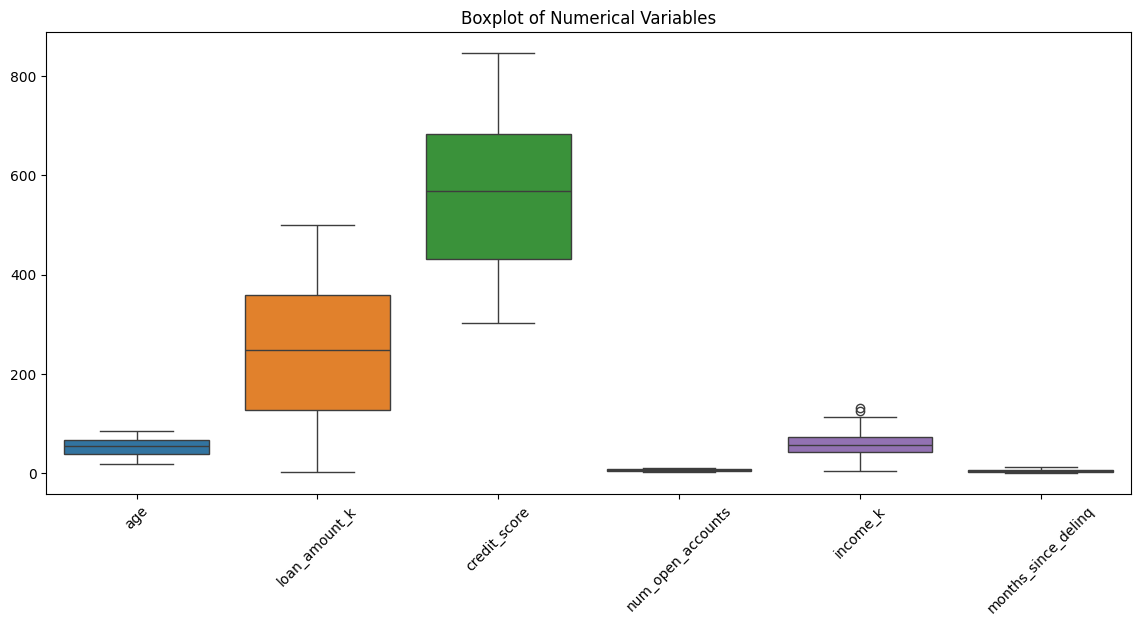

In [50]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df[numeric_columns])

plt.title("Boxplot of Numerical Variables")
plt.xticks(rotation=45)
plt.show()

## 17.4 Categorical Variable Analysis

Categorical variables represent groups or categories.

In this step, we calculate the frequency of each category in the home_owner, loan_purpose, and defaulted columns.

This helps us understand how many customers belong to each category.

In [51]:
categorical_columns = [
    'home_owner',
    'loan_purpose',
    'defaulted'
]

for col in categorical_columns:
    print("\nFrequency of", col)
    print(df[col].value_counts())


Frequency of home_owner
home_owner
No     137
Yes     94
Name: count, dtype: int64

Frequency of loan_purpose
loan_purpose
Business              69
Home improvement      43
Car                   41
Debt consolidation    39
Education             39
Name: count, dtype: int64

Frequency of defaulted
defaulted
0    203
1     28
Name: count, dtype: int64


## 17.5 Count Plot Visualization

A count plot is used to display the number of observations in each category.

It helps us compare the number of customers in different groups.

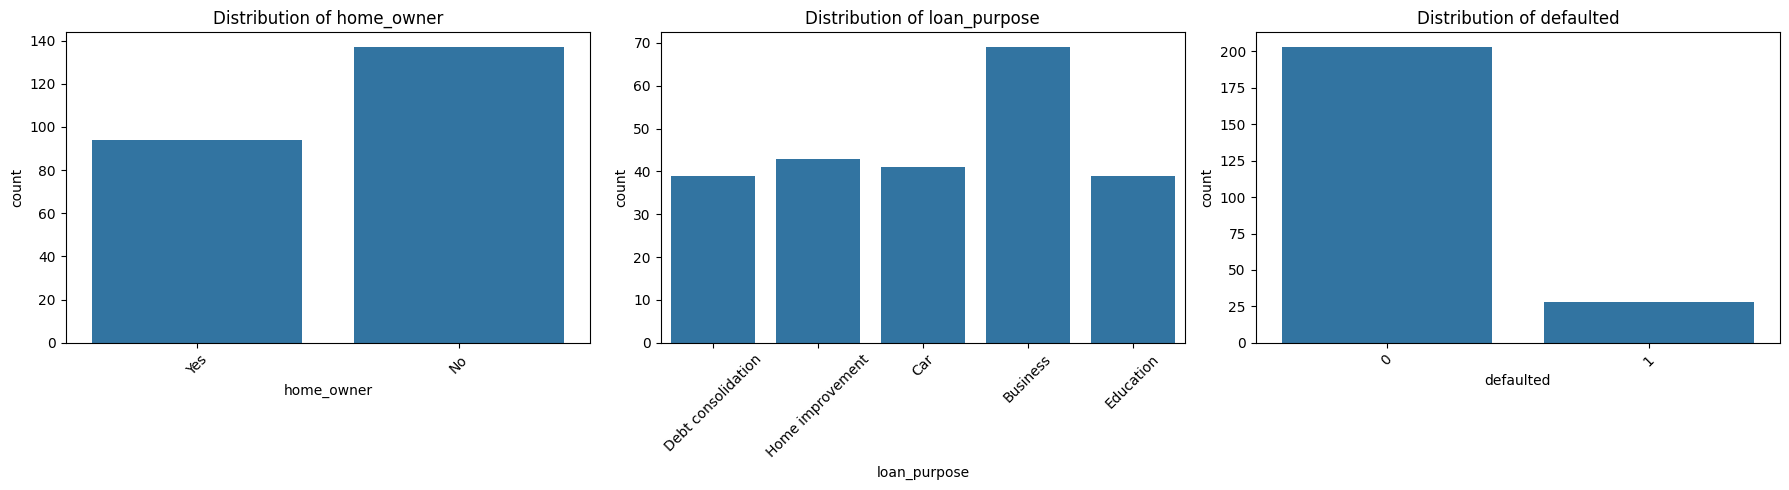

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, categorical_columns):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#Pie Chart – Home Ownership
This shows the percentage of customers who own a home and those who do not.

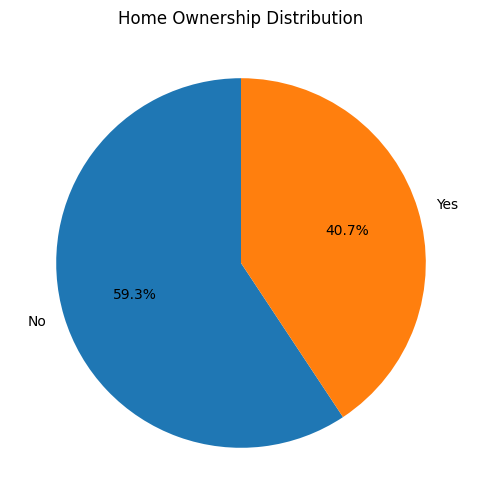

In [65]:
plt.figure(figsize=(6, 6))

df['home_owner'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Home Ownership Distribution')
plt.ylabel('')
plt.show()

# 18. Bivariate Analysis

Bivariate analysis is used to study the relationship between two variables.

It helps us understand how one variable changes in relation to another variable.

In this project, we compare numerical and categorical variables with the defaulted column.

## 18.1 Credit Score vs Default Status

In this analysis, we compare customers' credit scores with their loan default status.

A boxplot is used to compare the credit score distribution of customers who defaulted and those who did not default.

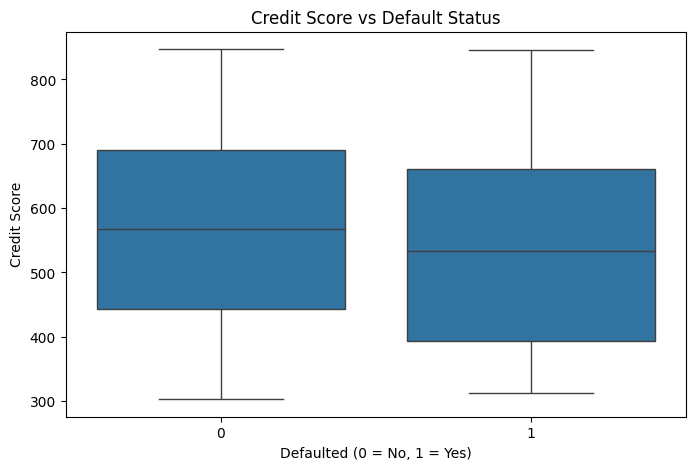

In [53]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='defaulted', y='credit_score')

plt.title("Credit Score vs Default Status")
plt.xlabel("Defaulted (0 = No, 1 = Yes)")
plt.ylabel("Credit Score")

plt.show()

## 18.2 Income vs Default Status

In this analysis, we compare customer income with their loan default status.

This helps us understand whether income levels differ between customers who defaulted and those who did not.

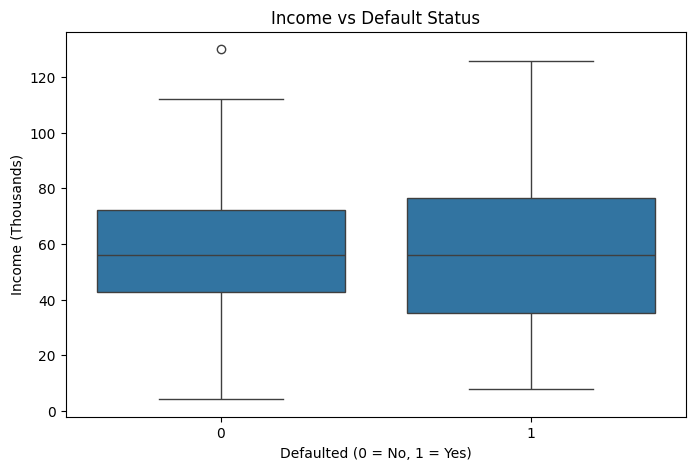

In [54]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='defaulted', y='income_k')

plt.title("Income vs Default Status")
plt.xlabel("Defaulted (0 = No, 1 = Yes)")
plt.ylabel("Income (Thousands)")

plt.show()

## 18.3 Loan Amount vs Default Status

In this analysis, we compare the loan amounts of customers based on their default status.

It helps us understand whether customers with different loan amounts show different default patterns.

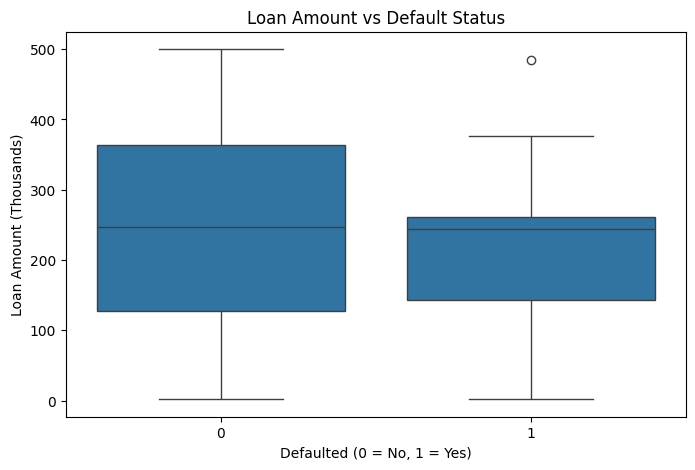

In [55]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='defaulted', y='loan_amount_k')

plt.title("Loan Amount vs Default Status")
plt.xlabel("Defaulted (0 = No, 1 = Yes)")
plt.ylabel("Loan Amount (Thousands)")

plt.show()

## 18.4 Age vs Default Status

In this analysis, we compare customer ages with their loan default status.

It helps us understand the distribution of ages among customers who defaulted and those who did not.

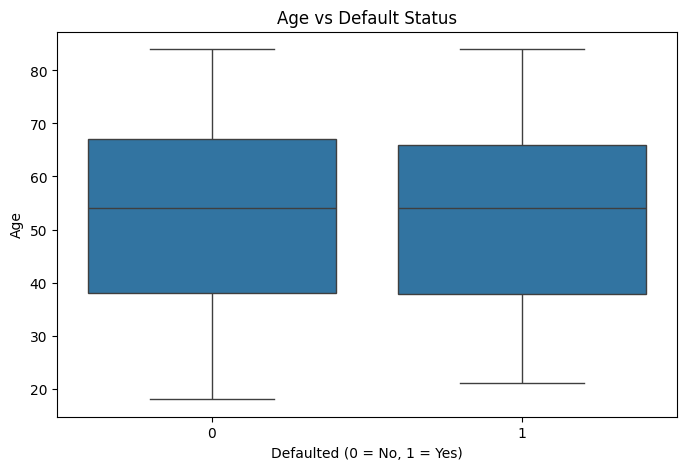

In [56]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='defaulted', y='age')

plt.title("Age vs Default Status")
plt.xlabel("Defaulted (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

## 18.5 Home Ownership vs Default Status

In this analysis, we compare home ownership with loan default status.

A bar chart is used to understand the number of customers who defaulted and did not default in each home ownership category.

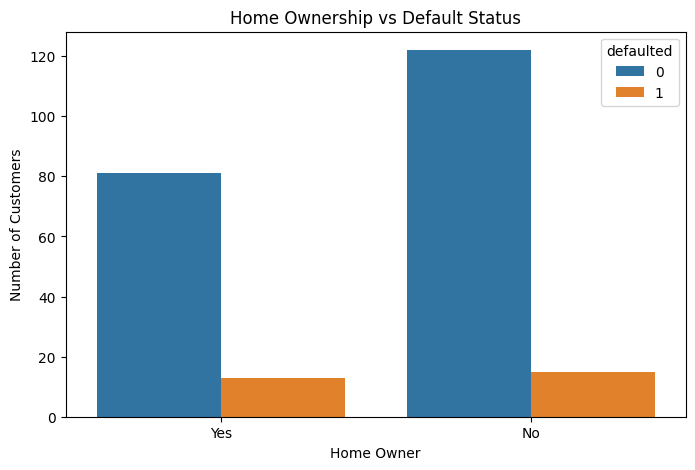

In [57]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='home_owner', hue='defaulted')

plt.title("Home Ownership vs Default Status")
plt.xlabel("Home Owner")
plt.ylabel("Number of Customers")

plt.show()

## 18.6 Loan Purpose vs Default Status

In this analysis, we compare the purpose of loans with the default status of customers.

It helps us understand which loan purposes have more default cases.

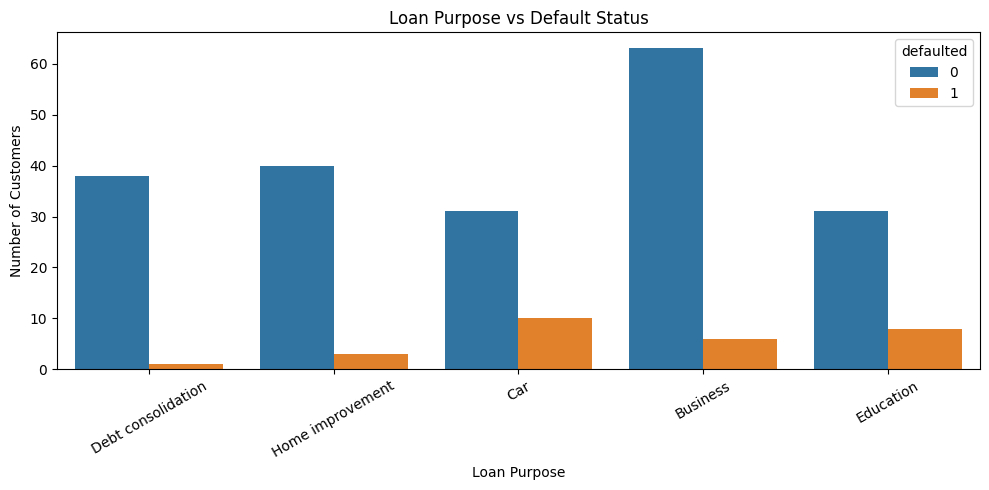

In [58]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='loan_purpose', hue='defaulted')

plt.title("Loan Purpose vs Default Status")
plt.xlabel("Loan Purpose")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## 18.7 Default Rate by Loan Purpose

In this analysis, we calculate the percentage of customers who defaulted for each loan purpose.

This helps us compare default rates instead of only comparing the total number of customers.

loan_purpose
Business               8.695652
Car                   24.390244
Debt consolidation     2.564103
Education             20.512821
Home improvement       6.976744
Name: defaulted, dtype: float64


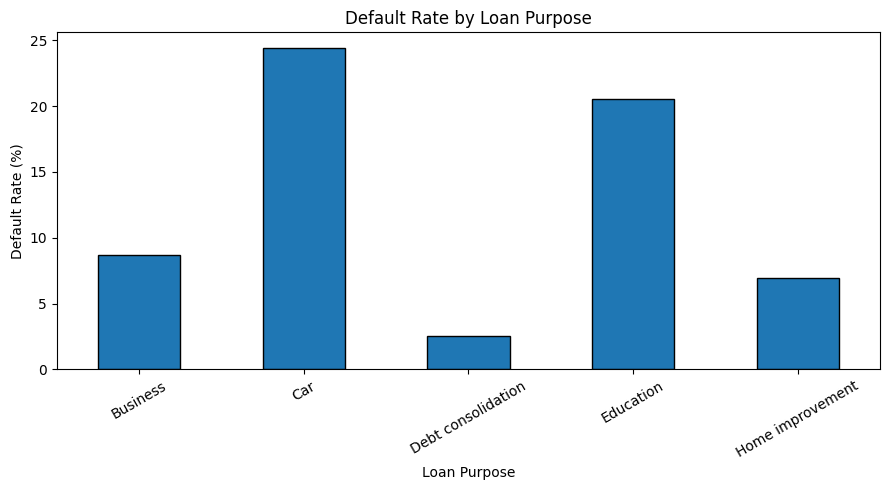

In [59]:
default_rate = df.groupby('loan_purpose')['defaulted'].mean() * 100

print(default_rate)

default_rate.plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# 19. Multivariate Analysis

Multivariate analysis is used to study three or more variables together.

It helps us understand complex relationships between different variables in a dataset.

In this project, we use correlation heatmaps, pair plots, and grouped analysis to understand relationships between customer details and loan default status.

## 19.1 Correlation Analysis

Correlation measures the relationship between numerical variables.

The correlation value ranges from -1 to +1.

- +1 indicates a strong positive relationship.
- -1 indicates a strong negative relationship.
- 0 indicates little or no linear relationship.

It helps us understand how numerical variables are related to each other.

In [60]:
correlation = df[numeric_columns + ['defaulted']].corr()

print(correlation)

                          age  loan_amount_k  credit_score  num_open_accounts  \
age                  1.000000      -0.085954      0.048537          -0.070419   
loan_amount_k       -0.085954       1.000000      0.031197           0.059833   
credit_score         0.048537       0.031197      1.000000           0.120865   
num_open_accounts   -0.070419       0.059833      0.120865           1.000000   
income_k             0.004593       0.030348      0.020349          -0.010883   
months_since_delinq -0.019324       0.035785     -0.029867          -0.013391   
defaulted            0.021723      -0.075688     -0.065395          -0.043945   

                     income_k  months_since_delinq  defaulted  
age                  0.004593            -0.019324   0.021723  
loan_amount_k        0.030348             0.035785  -0.075688  
credit_score         0.020349            -0.029867  -0.065395  
num_open_accounts   -0.010883            -0.013391  -0.043945  
income_k             1.000000  

## 19.2 Correlation Heatmap

A correlation heatmap is a graphical representation of correlation values between numerical variables.

Different colours represent different levels of correlation.

It helps us identify positive and negative relationships between variables.

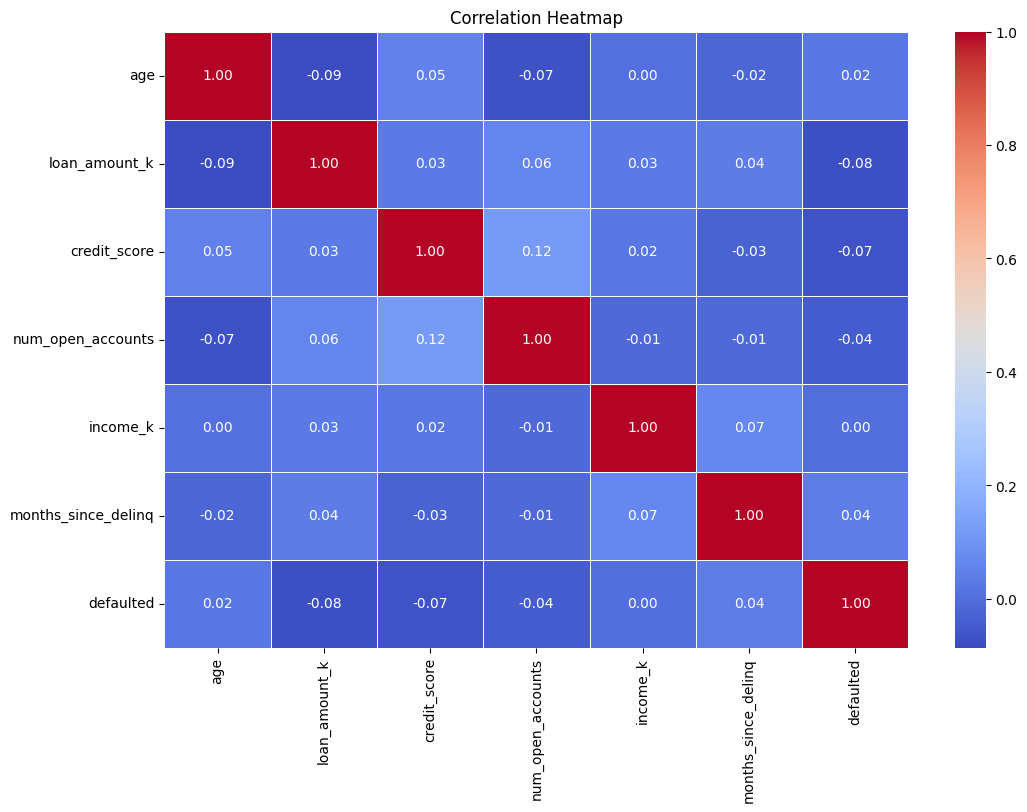

In [61]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

## 19.3 Pair Plot Analysis

A pair plot is used to compare multiple numerical variables with each other.

It displays scatter plots for relationships between two variables and histograms for individual variables.

We use different colours to identify customers based on their default status.

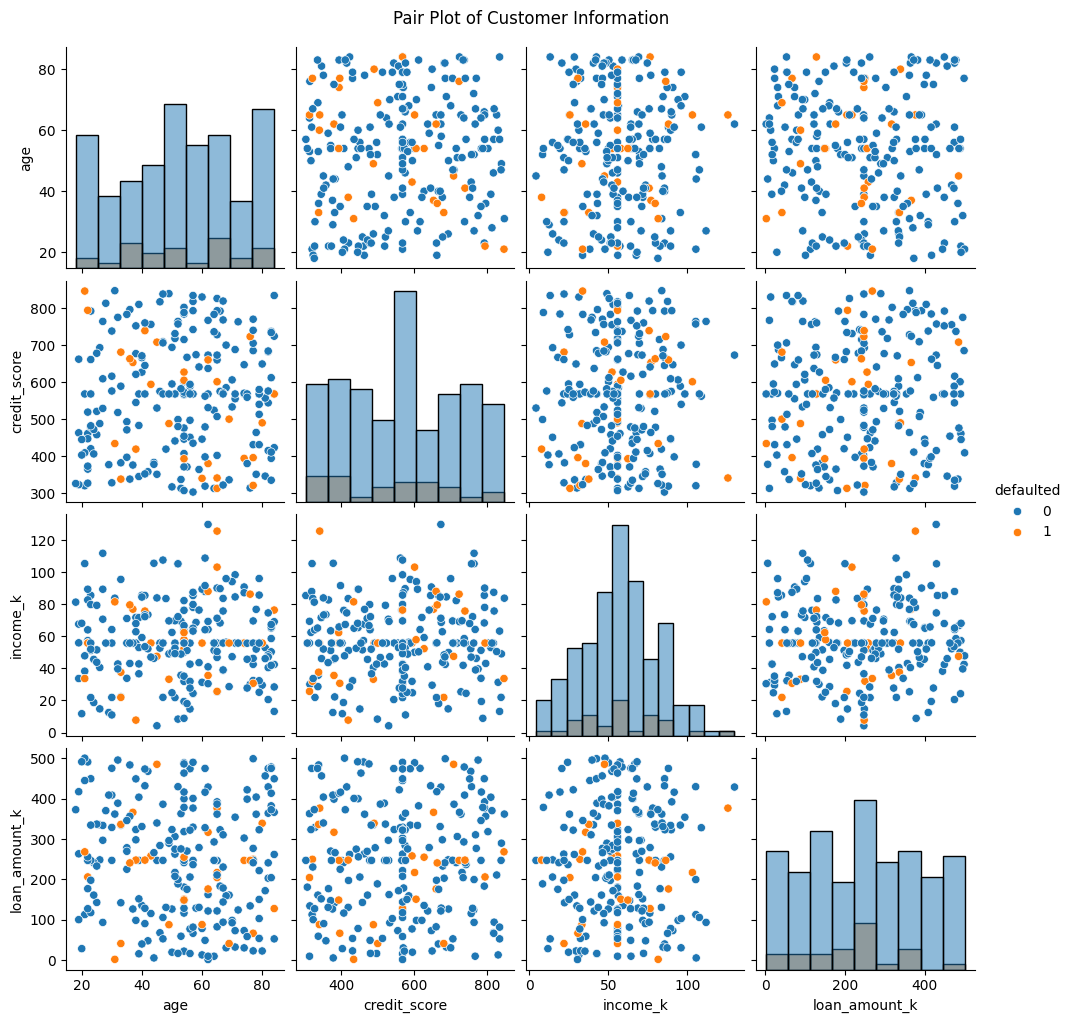

In [62]:
sns.pairplot(
    df,
    vars=[
        'age',
        'credit_score',
        'income_k',
        'loan_amount_k'
    ],
    hue='defaulted',
    diag_kind='hist'
)

plt.suptitle("Pair Plot of Customer Information", y=1.02)

plt.show()

## 19.4 Group Analysis

In this step, we analyze multiple categorical variables together.

We compare home ownership and loan purpose with the average default status.

This helps us understand how default rates differ among different customer groups.

home_owner                 No        Yes
loan_purpose                            
Business             7.142857  11.111111
Car                 21.428571  30.769231
Debt consolidation   0.000000   5.263158
Education           21.052632  20.000000
Home improvement     7.142857   6.666667


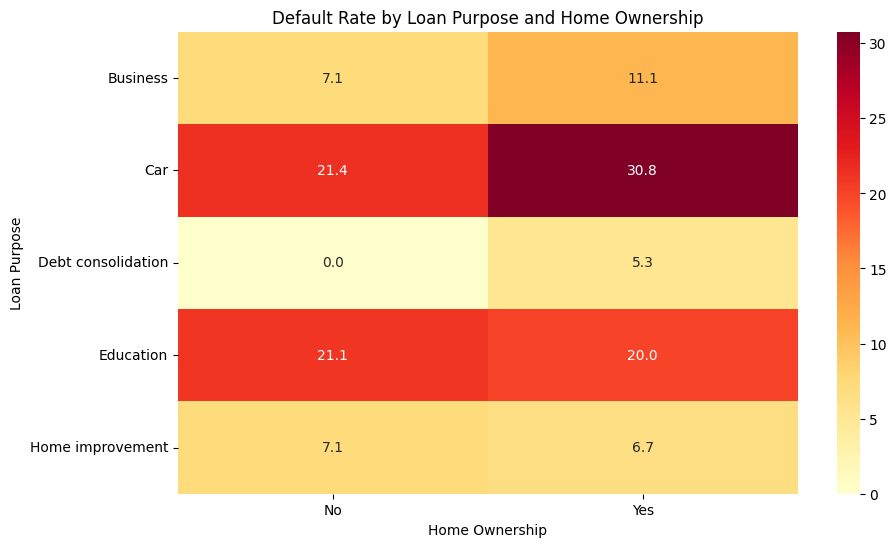

In [63]:
group_analysis = df.pivot_table(
    index='loan_purpose',
    columns='home_owner',
    values='defaulted',
    aggfunc='mean'
) * 100

print(group_analysis)

plt.figure(figsize=(10, 6))

sns.heatmap(
    group_analysis,
    annot=True,
    cmap='YlOrRd',
    fmt='.1f'
)

plt.title("Default Rate by Loan Purpose and Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Loan Purpose")

plt.show()

# 20. Final Observations

The following observations are made from the data analysis:

1. The dataset contains customer information such as age,id,income, credit score, and loan amount.
2. Data preprocessing helps remove duplicate records and handle missing and inconsistent values.
3. Univariate analysis helps understand individual variables and their distributions.
4. Bivariate analysis helps compare two variables and understand their relationships with loan default status.
5. Multivariate analysis helps study relationships between multiple variables using heatmaps and pair plots.
6. The analysis helps identify patterns and factors that may be associated with loan defaults.

# 21. Conclusion

In this project, the Credit Default Classification dataset was analyzed using Python in Google Colab.

First, the dataset was understood by checking its structure, columns, and statistical information.

Next, data preprocessing techniques were applied to handle missing values, duplicate records, inconsistent categorical values, and invalid income values.

After preprocessing, three types of data analysis were performed: univariate, bivariate, and multivariate analysis.

Different graphs such as histograms, boxplots, count plots, scatter plots, and correlation heatmaps were used to understand the dataset.

Finally, the analysis helped us understand customer information and identify patterns related to loan default status.